In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('tableau-colorblind10')

## AR(1) simulation
$y_t = c_t + \rho y_{t-1} + u_t, \quad \text{where} \quad c_t = \begin{cases}
0 & \text{for } t < t^*, \\
\bar{c} & \text{for } t \geq t^*.
\end{cases}$

Experiment by changing $\rho$ and $\bar{c}$.

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


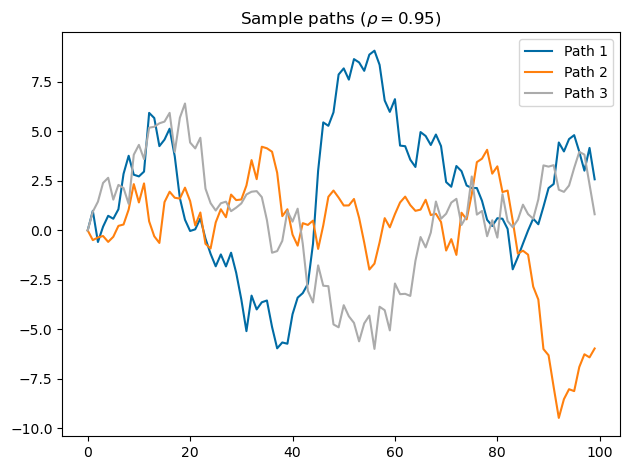

In [2]:
# Parameters
rho = 0.95
c_bar = 0
T = 100
n_paths = 3

# Simulate
rng = np.random.default_rng(seed=31150)
y = np.zeros((T, n_paths))
u = rng.standard_normal((T, n_paths))
for t in range(1, T):
    y[t] = rho * y[t - 1] + u[t]
    if t >= T // 2:
        y[t] += c_bar

# Plot
fig, ax = plt.subplots()
for j in range(n_paths):
    ax.plot(y[:, j], label=f'Path {j + 1}')
if c_bar != 0:
    ax.axvline(T // 2, color='black', linestyle='--', linewidth=0.8)
ax.set_title(f'Sample paths ($\\rho = {rho}$)')
ax.legend()
plt.tight_layout()
fig.savefig('output/ar_sim.eps')
plt.show()

## ACF of US unemployment rate

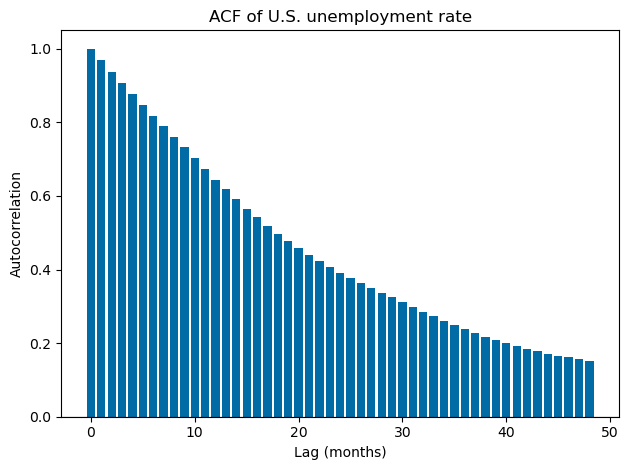

In [3]:
from statsmodels.tsa.stattools import acf

# Parameters
max_lag = 48

# Load data
df = pd.read_csv('data/UNRATE.csv', index_col='observation_date', parse_dates=True)
df = df.interpolate() # interpolate missing value in Oct 2025
y = df['UNRATE'].values

# Compute ACF
rho = acf(y, nlags=max_lag)

# Plot
fig, ax = plt.subplots()
ax.bar(range(max_lag + 1), rho, width=0.8)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xlabel('Lag (months)')
ax.set_ylabel('Autocorrelation')
ax.set_title('ACF of U.S. unemployment rate')
plt.tight_layout()
fig.savefig('output/unrate_acf.eps')
plt.show()

## Martingale difference sequence
$y_t = |u_{t-1}| \cdot u_t, \quad u_t \sim \text{iid } N(0,1)$

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


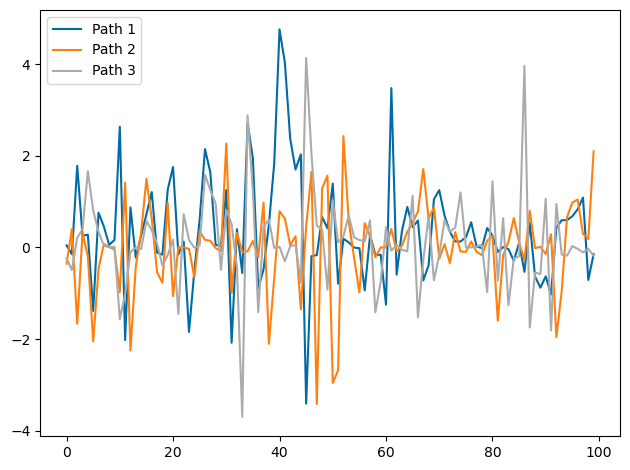

In [4]:
# Parameters
T = 100
n_paths = 3

# Simulate
y = np.zeros((T, n_paths))
u = rng.standard_normal((T+1, n_paths))
y = np.abs(u[:-1]) * u[1:]

# Plot
fig, ax = plt.subplots()
for j in range(n_paths):
    ax.plot(y[:, j], label=f'Path {j + 1}')
ax.legend()
plt.tight_layout()
fig.savefig('output/mds.eps')
plt.show()